# Experiment Design: Raising the Free-Shipping Threshold

**Business question:** An online UK gift wholesaler is considering raising its free shipping threshold.
Would this increase revenue per customer, and can an A/B test reliably measure the effect?

**Dataset:** UCI Online Retail, about 542K transaction lines from Dec 2010 to Dec 2011.

**Approach:** Use historical data to design the experiment before launch: define metrics and population,
estimate baselines and variance, compute sample size, apply variance reduction, and validate the full
pipeline by simulation.

**Key findings**
- Order values show strong **bunching just above £300**, suggesting an existing threshold. The experiment is
  reframed as raising it from **£300 to £400**.
- Revenue is extremely skewed and concentrated, top 1% of customers account for 41% of total revenue. With about 2,800 eligible
  customers, a naive test could only detect a **78%** lift in 4 weeks.
- Winsorization, CUPED, and matched pair assignment cut the MDE to **~25%**, which is validated by simulation, still
  far above a realistic approximately 5% effect.
- A/A simulation confirms the final design is calibrated ,false positive rate ≈ 5%, while analyzing at the
  order level instead of the customer level inflates it to **33%**.
- **Recommendation:** do not run a standard superiority test on revenue. Clarify the business goal and use a
  non-inferiority framework on margin with a staged rollout (Section 7).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## 1. Experiment Definition

**Scenario:** The product team proposes a free shipping threshold to encourage customers to add items and
qualify. Before launch, the experiment answers the following, what to test, how to assign, what to measure, and how
long to run. Since Section 2 shows a threshold likely already exists at £300, the proposal is refined to
raising it to £400.

### Randomization unit: customer instead of order
- **Consistent experience:** a customer who sees free shipping on one order but not the next would be
  confused, and might time purchases around it.
- **Independence:** orders from the same customer are correlated ,large customers place many large orders.
  Randomizing or analyzing by order would underestimate variance and inflate false positives .Section 6A
  shows by how much.
- **Carryover:** treatment on one order can affect the customer's later orders.

**The analysis unit must match the randomization unit**, therefore the primary metrics are computed per customer.

### Metrics
| Type | Metric | Rationale |
|---|---|---|
| **Primary** | Net revenue per customer | Reflects the business goal; not confused by order consolidation |
| Secondary | Average order value (AOV); orders per customer | Explain *how* revenue changes |
| **Guardrail** | Margin after shipping costs; cancellation rate; purchase rate | Ensure no harm elsewhere |

**Why not AOV as the primary metric?** A customer who replaces three £100 orders with one £250 order raises
AOV by 150% while spending *less* in total, and the company may pay more in shipping.

### Population
Customers who purchased in a pre period before the experiment, revenue measured during the experiment
window and non buyers counted as £0. Defining the population before launch avoids selecting on an outcome
the treatment could affect.

## 2. Data Cleaning and Exploration

In [47]:
import os

print(os.getcwd())

/Users/hullyji/A:B test project/2/notebook


In [48]:
retail = pd.read_excel("../data/Online Retail.xlsx")

In [49]:
print(retail.shape)

(541909, 8)


In [6]:
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str)
retail["StockCode"] = retail["StockCode"].astype(str)
print("Raw rows:", len(retail))

Raw rows: 541909


In [7]:
# --- 1. Drop rows without CustomerID ---
retail = retail[retail["CustomerID"].notna()].copy()
print("After dropping missing CustomerID:", len(retail))

After dropping missing CustomerID: 406829


In [8]:
# --- 2. Keep product lines only ---
# No product codes: postage, manual adjustments, fees, discount
is_product = retail["StockCode"].str.match(r"^\d{5}")
print(retail.loc[~is_product, "Description"].value_counts().head(10))
retail = retail[is_product].copy()

Description
POSTAGE                       1196
Manual                         465
CARRIAGE                       134
Discount                        77
DOTCOM POSTAGE                  16
CRUK Commission                 16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       4
Name: count, dtype: int64


In [9]:
# --- 3. drop non positive prices ---
retail = retail[retail["UnitPrice"] > 0].copy()
print("After dropping non positive prices:", len(retail))

After dropping non positive prices: 404876


In [10]:
# --- 4. revenue and cancellation flag ---
retail["revenue"] = retail["Quantity"] * retail["UnitPrice"]
retail["is_cancel"] = retail["InvoiceNo"].str.startswith("C")
print(f"Cancellaation lines: {retail['is_cancel'].sum():,}")

Cancellaation lines: 8,539


In [11]:
# --- 5. inspect the largest orders ---
orders = (retail[~retail["is_cancel"]].groupby("InvoiceNo")
          .agg(customer=("CustomerID", "first"), date=("InvoiceDate", "first"),
          revenue=("revenue", "sum"), n_lines=("StockCode", "size")))
print(orders.sort_values("revenue", ascending=False).head(5))

           customer                date    revenue  n_lines
InvoiceNo                                                  
581483      16446.0 2011-12-09 09:15:00  168469.60        1
541431      12346.0 2011-01-18 10:01:00   77183.60        1
556444      15098.0 2011-06-10 15:28:00   38970.00        1
567423      17450.0 2011-09-20 11:05:00   31698.16       12
556917      12415.0 2011-06-15 13:37:00   22775.93      138


In [12]:
suspicious = ["581483", "C581484", "541431", "C541433", "556444"]
print(retail[retail["InvoiceNo"].isin(suspicious)]
      [["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate"]])

       InvoiceNo                     Description  Quantity  UnitPrice  \
61619     541431  MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04   
61624    C541433  MEDIUM CERAMIC TOP STORAGE JAR    -74215       1.04   
222680    556444  PICNIC BASKET WICKER 60 PIECES        60     649.50   
540421    581483     PAPER CRAFT , LITTLE BIRDIE     80995       2.08   
540422   C581484     PAPER CRAFT , LITTLE BIRDIE    -80995       2.08   

               InvoiceDate  
61619  2011-01-18 10:01:00  
61624  2011-01-18 10:17:00  
222680 2011-06-10 15:28:00  
540421 2011-12-09 09:15:00  
540422 2011-12-09 09:27:00  


In [13]:
# --- 6.remove the cancelled outlier orders ---
retail = retail[~retail["InvoiceNo"].isin(suspicious)].copy()
print("After removing cancelled outlier orders:", len(retail))

After removing cancelled outlier orders: 404871


In [14]:
# --- Order-level summary (purchases only) ---
# 订单层面的描述统计（只看购买，不含取消）
orders = (retail[~retail["is_cancel"]].groupby("InvoiceNo")
          .agg(customer=("CustomerID", "first"), date=("InvoiceDate", "first"),
               revenue=("revenue", "sum")))

n_weeks = (orders["date"].max() - orders["date"].min()).days / 7
print(f"Orders: {len(orders):,} | Customers: {orders['customer'].nunique():,}")
print(f"Date range: {orders['date'].min():%Y-%m-%d} to {orders['date'].max():%Y-%m-%d}")
print(f"Orders per week: {len(orders) / n_weeks:.0f}")
print(orders["revenue"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))
print(f"Skewness: {orders['revenue'].skew():.1f}")

top1_cutoff = orders["revenue"].quantile(0.99)
top1_share = orders.loc[orders["revenue"] >= top1_cutoff, "revenue"].sum() / orders["revenue"].sum()
print(f"Share of revenue from top 1% of orders: {top1_share:.1%}")

Orders: 18,399 | Customers: 4,333
Date range: 2010-12-01 to 2011-12-09
Orders per week: 345
count    18399.0
mean       460.7
std        940.5
min          0.4
25%        157.8
50%        302.2
75%        464.9
90%        811.1
99%       3706.0
max      31698.2
Name: revenue, dtype: float64
Skewness: 12.5
Share of revenue from top 1% of orders: 16.3%


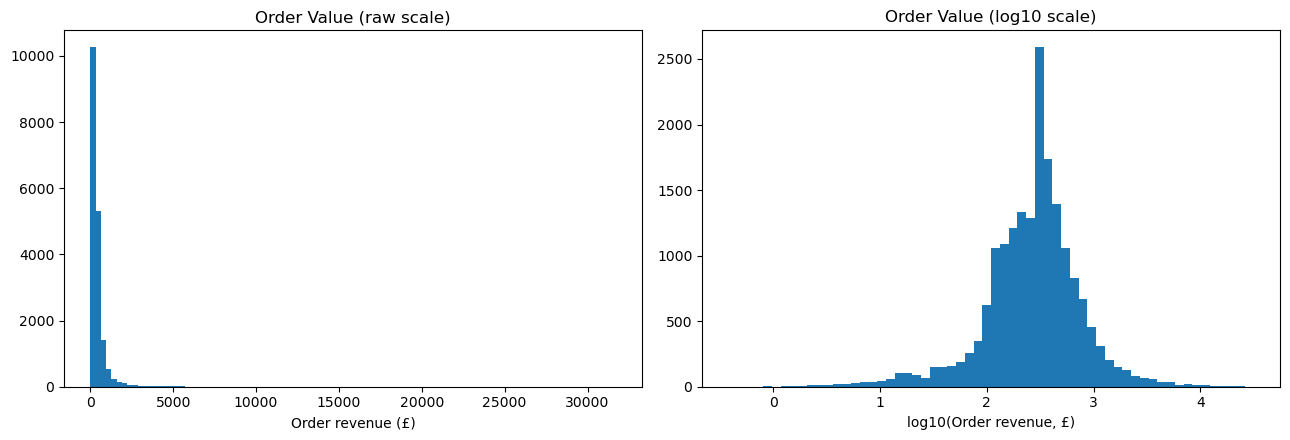

In [15]:
# --- Distribution plot ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(orders["revenue"], bins=100, color="tab:blue")
axes[0].set_title("Order Value (raw scale)")
axes[0].set_xlabel("Order revenue (£)")

axes[1].hist(np.log10(orders["revenue"]), bins=60, color="tab:blue")
axes[1].set_title("Order Value (log10 scale)")
axes[1].set_xlabel("log10(Order revenue, £)")

plt.tight_layout()
plt.show()

### Order value distribution

| Metric | Value |
|---|---|
| Orders / customers | 18,399 / 4,333 |
| Orders per week | ~345 |
| Mean / median order value | £460.7 / £302.2 |
| Standard deviation | £940.5 |
| Skewness | 12.5 |
| Revenue share of top 1% of orders | 16.3% |

The distribution is heavily right skewed: the mean is 50% above the median, the SD is twice the mean, and the
top 1% of orders bring 16% of revenue. On a log scale it is roughly bell shaped ,approximately log-normal,
which is typical of monetary data. High variance makes revenue experiments much harder than conversion
experiments, since required sample size scales with variance.

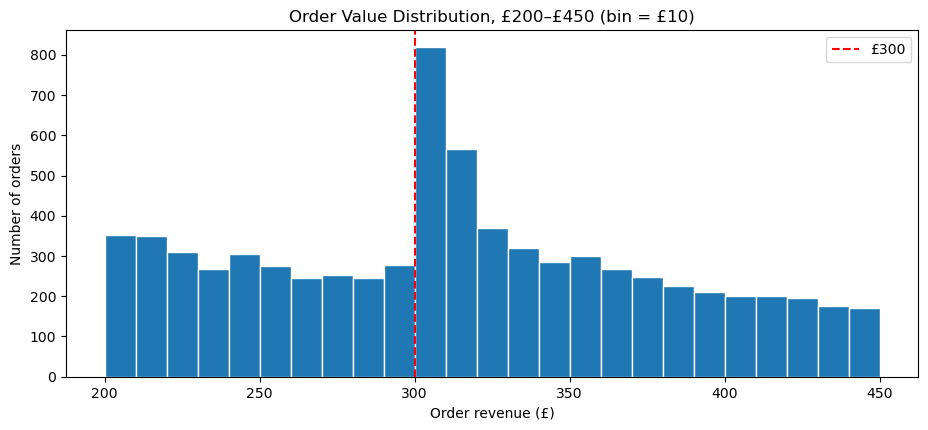

In [16]:
# --- Zoom in: bunching around £300 ---
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(orders["revenue"], bins=np.arange(200, 451, 10), color="tab:blue", edgecolor="white")
ax.axvline(300, color="red", linestyle="--", label="£300")
ax.set_title("Order Value Distribution, £200–£450 (bin = £10)")
ax.set_xlabel("Order revenue (£)")
ax.set_ylabel("Number of orders")
ax.legend()
plt.show()

### Key Finding: Bunching at £300

The log scale distribution shows a sharp spike around £300. Zooming in with £10 bins:

| Order value | Orders |
|---|---|
| £280–290 | 248 |
| £290–300 | 279 |
| **£300–310** | **819** |
| **£310–320** | **566** |
| £320–330 | 369 |
| £330–340 | 319 |

Orders just above £300 are roughly 3 times more frequent than in neighboring bins. The bunching pattern, suggests customers deliberately push their orders over £300. The most likely explanation is an existing threshold at around £300, such as free shipping, a wholesale minimum, or a volume discount. The data contain no direct evidence, therefore this remains an inference.

**Implications for the experiment design:**

1. **Thresholds do change customer behavior.** Customers add items to cross the threshold, which provides
   real world support for the hypothesis that a threshold can increase spending.
2. **It reframes the experiment.** If a £300 threshold already exists, the more relevant question is not
   whether to introduce a free shipping threshold, but **whether raising it from £300 to £400 would increase
   customer spending**. This makes the experiment more realistic for this business.
3. **It makes the order consolidation risk more concrete.** After raising the threshold, some customers may
   add items to reach £400, while others may place fewer orders or stop buying altogether instead. This is why the
   primary metric should be **revenue per customer**, not AOV.

**Revised hypothesis:** Raising the free shipping threshold from £300 to £400 increases revenue per customer.

In [17]:
# --- Define time windows, pre experiment 6 months, experiment 4 weeks ---
retail["date"] = retail["InvoiceDate"].dt.normalize()
exp_start = pd.Timestamp("2011-09-01")
pre_months = 6
exp_weeks = 4
pre_start = exp_start - pd.DateOffset(months=pre_months)
exp_end = exp_start + pd.Timedelta(weeks = exp_weeks)
print(f"pre period: {pre_start:%Y-%m-%d} to {exp_start - pd.Timedelta(days=1):%Y-%m-%d}")
print(f"experiment: {exp_start:%Y-%m-%d} to {exp_end - pd.Timedelta(days=1):%Y-%m-%d}")
pre = retail[(retail["date"] >= pre_start) & (retail["date"] < exp_start)]
exp = retail[(retail["date"] >= exp_start) & (retail["date"] < exp_end)]

pre period: 2011-03-01 to 2011-08-31
experiment: 2011-09-01 to 2011-09-28


In [18]:
# --- build customer level table
# eligible population: customers with at least one purchase in the pre period
pre_buyers = pre.loc[~pre['is_cancel'], "CustomerID"].unique()
cust = pd.DataFrame(index=pd.Index(pre_buyers, name="customerID"))
# pre period net revenue
cust = cust.join(pre.groupby("CustomerID")["revenue"].sum().rename("pre_revenue"))
# experiment period net revenue and order count, non buyers label as 0
exp_revenue = exp.groupby("CustomerID")["revenue"].sum().rename("revenue")
exp_orders = (exp.loc[~exp["is_cancel"]].groupby("CustomerID")["InvoiceNo"]
             .nunique().rename("n_orders"))
cust = cust.join(exp_revenue).join(exp_orders).fillna({"revenue": 0, "n_orders":0})
cust["purchased"] = (cust["n_orders"]>0).astype(int)
print(f"eligible customer: {len(cust):,}")
print(cust.describe().round(2))

eligible customer: 2,809
       pre_revenue   revenue  n_orders  purchased
count      2809.00   2809.00   2809.00    2809.00
mean       1227.19    244.61      0.44       0.30
std        4316.18   1806.86      1.01       0.46
min       -1573.65   -561.60      0.00       0.00
25%         240.68      0.00      0.00       0.00
50%         479.70      0.00      0.00       0.00
75%        1099.44    176.20      1.00       1.00
max      117721.92  68467.28     26.00       1.00


In [19]:
# --- baseline metric and variance ---
mean_rev, sd_rev = cust["revenue"].mean(), cust["revenue"].std()
print(f"revenue per customer: mean = £{mean_rev:.1f}, median = £{cust['revenue'].median():.1f}, "
      f"sd = £{sd_rev:.1f}")
print(f"coefficient of variation (sd / mean): {sd_rev / mean_rev:.2f}")
print(f"skewness: {cust['revenue'].skew():.1f}")
print(f"purchase rate in window: {cust['purchased'].mean():.1%}")
buyers = cust[cust["purchased"] == 1]
print(f"Among buyers: mean = £{buyers['revenue'].mean():.1f}, median = £{buyers['revenue'].median():.1f}")
# --- revenue concentration ---
rev_sorted = cust["revenue"].sort_values(ascending=False)
for share in [0.01, 0.05, 0.1]:
    k = int(len(cust)*share)
    print(f"Top {share:.0%} of customers ({k}) -> {rev_sorted.iloc[:k].sum() / rev_sorted.sum():.1%} of revenue")
# --- correlation between pre period and experiment period revenue ---
print(f"correlation(pre_revenue, revenue): {cust['pre_revenue'].corr(cust['revenue']):.2f}")


revenue per customer: mean = £244.6, median = £0.0, sd = £1806.9
coefficient of variation (sd / mean): 7.39
skewness: 28.4
purchase rate in window: 30.1%
Among buyers: mean = £814.0, median = £370.8
Top 1% of customers (28) -> 40.8% of revenue
Top 5% of customers (140) -> 63.4% of revenue
Top 10% of customers (280) -> 77.2% of revenue
correlation(pre_revenue, revenue): 0.73


## 3. Customer Level Baseline Metrics

### Simulated experiment window
Historical data is used to estimate what the baseline and variance would look like if the experiment had
been run.

| Period | Dates | Purpose |
|---|---|---|
| Pre period | Mar 1 – Aug 31, 2011 (6 months) | Define the eligible population; pre-experiment spend for cuped and stratification |
| Experiment period | Sep 1 – Sep 28, 2011 (4 weeks) | Primary metric: net revenue per customer |

September was chosen to avoid the November to December as holiday peak, which would inflate the baseline and
not represent typical behavior.

### Population and metric definition
- **Eligible population:** 2,809 customers with at least one purchase in the pre period. The
  population is fixed *before* the experiment starts, so it cannot be affected by the treatment.
- **Primary metric:** net revenue per customer during the experiment window. Customers who did not purchase
  are kept with revenue = £0. If the new threshold discourages some customers from buying, that loss is part
  of the treatment effect and shall be captured.
- **Net revenue** includes cancellations as negative revenue. A few customers have negative net revenue
  because they cancelled orders placed before the window.

### Baseline results
| Metric | Value |
|---|---|
| Eligible customers | 2,809 |
| Purchase rate in 4 week window | 30.1% |
| Revenue per customer: mean / median | £244.6 / £0 |
| Standard deviation | £1,806.9 |
| Coefficient of variation (sd / mean) | 7.39 |
| Skewness | 28.4 |
| Among buyers: mean / median | £814.0 / £370.8 |
| Revenue share of top 1% of customers (28) | 40.8% |
| Revenue share of top 10% of customers (280) | 77.2% |
| Correlation(pre period revenue, experiment revenue) | 0.73 |

### Interpretation
- **Very high variance.** The CV of 7.39 compares with about 2.7 for the binary conversion metric in Part 1.
  Since required sample size scales with CV², detecting the same relative lift needs roughly 7.5 times more
  units per group, while this population has only 2,809 customers.
- **Zero inflated and long tailed.** 70% of customers spend nothing in the window, while a few spend very
  large amounts.
- **Highly concentrated revenue.** 28 customers account for 41% of revenue. Under simple randomization, the
  chance allocation of these few customers could dominate the result. Mitigations:
  - **Stratified randomization:** split customers into tiers by pre-period spend and randomize within each
    tier, guaranteeing balance of large customers across groups.
  - **cuped:** adjust for pre period spend at the analysis stage.
  - **Winsorization:** cap extreme values to limit the influence of individual customers.
- **Strong pre/post correlation (0.73).** Much of the variation reflects stable differences between customers.
  cuped can remove this by theoretically reducing variance for about 1 − 0.73² ≈ 53%.

In [20]:
# --- reusable function: build customer table for a given window ---
def build_customer_table(retail, exp_start, exp_weeks,pre_months=6):
    pre_start = exp_start - pd.DateOffset(months=pre_months)
    exp_end = exp_start + pd.Timedelta(weeks=exp_weeks)
    exp_end = exp_start + pd.Timedelta(weeks=exp_weeks)

    pre = retail[(retail["date"] >= pre_start) & (retail["date"] < exp_start)]
    exp = retail[(retail["date"] >= exp_start) & (retail["date"] < exp_end)]

    pre_buyers = pre.loc[~pre["is_cancel"], "CustomerID"].unique()
    cust = pd.DataFrame(index=pd.Index(pre_buyers, name="CustomerID"))
    cust = cust.join(pre.groupby("CustomerID")["revenue"].sum().rename("pre_revenue"))

    exp_revenue = exp.groupby("CustomerID")["revenue"].sum().rename("revenue")
    exp_orders = (exp.loc[~exp["is_cancel"]].groupby("CustomerID")["InvoiceNo"]
                  .nunique().rename("n_orders"))
    cust = cust.join(exp_revenue).join(exp_orders).fillna({"revenue": 0, "n_orders": 0})
    cust["purchased"] = (cust["n_orders"] > 0).astype(int)
    return cust

In [21]:
# --- sample size and MDE for a continuous metric ---
alpha, power = 0.05, 0.80
z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta = stats.norm.ppf(power)

def required_n_continuous(sd, abs_effect):
    return 2 * (z_alpha + z_beta) ** 2 * sd ** 2 / abs_effect ** 2
def mde_continuous(sd, n_per_group):
    return (z_alpha + z_beta) * np.sqrt(2 * sd ** 2 / n_per_group)

In [22]:
# --- compare different window length --- 
rows = []
for weeks in [4, 8, 12]:
    c = build_customer_table(retail, exp_start, weeks)
    m, sd = c["revenue"].mean(), c["revenue"].std()
    n_per_group = len(c) // 2
    rows.append({
        "weeks": weeks,
        "customers": len(c),
        "purchase_rate": round(c["purchased"].mean(), 3),
        "mean_rev": round(m, 1),
        "sd_rev": round(sd, 1),
        "cv": round(sd / m, 2),
        "mde_relative": f"{mde_continuous(sd, n_per_group) / m:.1%}",
        "n_needed_5pct": int(np.ceil(required_n_continuous(sd, 0.05 * m))),
        "n_needed_10pct": int(np.ceil(required_n_continuous(sd, 0.10 * m)))
    })
window_df = pd.DataFrame(rows)
print(window_df.to_string(index=False))

 weeks  customers  purchase_rate  mean_rev  sd_rev   cv mde_relative  n_needed_5pct  n_needed_10pct
     4       2809          0.301     244.6  1806.9 7.39        78.1%         342600           85650
     8       2809          0.471     493.4  2937.9 5.95        63.0%         222641           55661
    12       2809          0.587     786.8  3933.0 5.00        52.9%         156891           39223


## 4. Sample Size and Experiment Duration

### Expected effect size
Raising the threshold from £300 to £400 only affects customers whose orders fall near the threshold, and
two opposing behaviors (adding items to reach £400 vs. ordering less or not at all) partially offset each
other. A realistic effect on revenue per customer is in the **single digit percent range**, for example about 5%.

### Formulas continuous metric
- Required sample size per group: n = 2 (z₁₋α/₂ + z₁₋β)² σ² / δ²
- Minimum detectable effect: MDE = (z₁₋α/₂ + z₁₋β) · √(2σ² / n)

with α = 0.05 (two-sided) and power = 80%.

### Results
The eligible population is fixed at 2,809 customers (~1,404 per group).

| Window | Purchase rate | Mean revenue | SD | CV | MDE (relative) | n per group for 5% lift | n per group for 10% lift |
|---|---|---|---|---|---|---|---|
| 4 weeks | 30.1% | £244.6 | £1,806.9 | 7.39 | 78.1% | 342,600 | 85,650 |
| 8 weeks | 47.1% | £493.4 | £2,937.9 | 5.95 | 63.0% | 222,641 | 55,661 |
| 12 weeks | 58.7% | £786.8 | £3,933.0 | 5.00 | 52.9% | 156,891 | 39,223 |

### Interpretation
- **The experiment is not feasible as designed.** With a 4 week window, only a 78% lift would be reliably
  detected, far above the plausible ~5% effect. Detecting a 5% lift would require about 342,600 customers per
  group, about 240 times the available population.
- **Running longer helps, but only slightly.** Unlike website experiments, where new users keep arriving,
  this population is fixed, so a longer window does not increase n. It helps only because each customer's
  revenue accumulates, making the metric less zero inflated (purchase rate rises from 30% to 59%, CV falls
  from 7.39 to 5.00). Tripling the duration lowers the MDE only from 78% to 53%.
- **Longer windows carry costs:** opportunity cost of not testing other ideas, seasonality ,the 12 week window
  reaches the late November holiday peak, and prolonged exposure to a potentially harmful change.

### Options when an experiment is underpowered
1. **Reduce variance:** winsorization, CUPED, stratified randomization (Section 5).
2. **Use a more sensitive metric**, closer to the change, for example, share of orders reaching the threshold.
3. **Accept a larger MDE**, if only large effects would justify launching.
4. **Use alternative evaluation methods**, such as a staged rollout with pre/post comparison or
   quasi experimental methods, or decide without a test if the change is low risk and easy to reverse.

### Launch Decision Without a Conclusive Test

A natural reaction to an underpowered test is: *"If we can't measure it, let's just launch."* But launch
decisions are **not symmetric**. "Launch if it works, don't if it doesn't" treats both kinds of error as
equally costly, which is rarely true.

**Sources of asymmetry**
1. **Different costs of error.** Launching a harmful change ,analogous to a Type I error could drive
   customers away. Wholesale customers who switch suppliers are hard to win back, even if the change is
   reverted. Not launching a beneficial change ,analogous to a Type II error forgoes some upside, but the
   status quo does not get worse. When error costs differ, the side with the higher cost requires stronger
   evidence.
2. **Different reversibility.** A button color can be changed back with little notice. Pricing and shipping
   policies are visible to customers, and changing them back and forth erodes trust. Wholesale customers may
   have built purchasing habits around the £300 threshold.
3. **Change has its own cost.** Implementation, communication, and maintenance costs mean that "no change"
   is the default, and a change needs a reason, consistent with the conclusion in Part 1.

**Reframing the goal: cost savings and non-inferiority**
A business motive for raising the threshold may be **reducing shipping costs**: fewer orders qualify for
free shipping, so the company absorbs less shipping expense. If so, the experiment does not need to show that
revenue *increases*, only that it does **not decrease meaningfully** while margin improves.

**Reframing the goal: cost savings and non-inferiority**
A business motive for raising the threshold may be **reducing shipping costs**: fewer orders qualify for
free shipping, so the company absorbs less shipping expense. If so, the experiment does not need to show that
revenue *increases*, only that it does **not decrease meaningfully** while margin improves.

This calls for a **non-inferiority test**:
- H₀: the new threshold reduces revenue per customer by more than an acceptable margin (e.g. 2%)
- H₁: any reduction is within the acceptable margin

Margin per customer (after shipping costs) would become the primary metric, with revenue as a guardrail.
Non-inferiority designs are common for cost-saving changes, where the goal is to confirm "no meaningful
harm" rather than "clear improvement."

**Recommendation: do not launch to all customers without evidence**
Revenue is highly concentrated, so losing even a few large customers would be costly and hard to reverse. Instead:
- **Staged rollout:** launch first to a lower risk segment (e.g. new or smaller customers) while keeping the
  current threshold for top-tier customers.
- **Pre-defined rollback criteria:**  revert if repeat purchase rate drops beyond a set threshold, or if
  key accounts reduce orders within the first weeks.
- **Align the metric with the true goal:** if the objective is cost reduction, evaluate margin as the
  primary metric under a non inferiority framework.

The role of data science here is not only to compute p values but to help the team make sound decisions
under uncertainty: an inconclusive test calls for a different way of managing risk, not for abandoning
judgment.

In [23]:
# --- Winsorization ---
def winsorize(s,q):
    return s.clip(upper=s.quantile(q))
for q in [0.99, 0.95]:
    print(f"{q:.0%} cap :£{cust['revenue'].quantile(q):,.0f}")

99% cap :£2,607
95% cap :£885


In [24]:
# --- cuped --
# Y_cuped = Y - theta * (X - mean(X)), where theta = cov(X,Y) / var(x)
# X must be a pre experiment covariate, unaffected by the treatment
def cuped(y, x):
    theta = np.cov(x, y, ddof=1)[0,1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta
y_cuped, theta = cuped(cust["revenue"], cust["pre_revenue"])
rho = cust["revenue"].corr(cust["pre_revenue"])
print(f"theta = {theta:.3f}, rho = {rho:.2f}")
print(f"theoretical variance ratio (1-rho^2): {1-rho**2:.1%}")
print(f"actual variance ratio:{y_cuped.var()/cust['revenue'].var():.1%}")
print(f"mean before/after cuped: {cust['revenue'].mean():.1f} / {y_cuped.mean():.1f}")

theta = 0.304, rho = 0.73
theoretical variance ratio (1-rho^2): 47.3%
actual variance ratio:47.3%
mean before/after cuped: 244.6 / 244.6


In [25]:
# --- compare all methods ---
# when winsorizing, cap the covariate too, so cuped is not driven by outlier in X
def compare_methods(cust):
    n = len(cust) // 2
    y, x = cust["revenue"], cust["pre_revenue"]
    metrics = {"Raw": y, "cuped": cuped(y,x)[0]}
    for q in [0.99, 0.95]:
        y_w, x_w = winsorize(y, q), winsorize(x, q)
        metrics[f"Winsorized p{q * 100:.0f}"] = y_w
        metrics[f"winsorize p{q * 100:.0f} + cuped"] = cuped(y_w, x_w)[0]
    rows = []
    for name, m in metrics.items():
        rows.append({"method": name,
                     "mean": round(m.mean(), 1),
                     "sd": round(m.std(), 1),
                     "variance_vs_raw": f"{m.var() / y.var():.1%}",
                     "mde_relative": f"{mde_continuous(m.std(), n) / m.mean():.1%}"})
    return pd.DataFrame(rows)
for weeks in [4, 12]:
    print(f"\n==={weeks}-week window ===")
    print(compare_methods(build_customer_table(retail, exp_start, weeks)).to_string(index=False))


===4-week window ===
               method  mean     sd variance_vs_raw mde_relative
                  Raw 244.6 1806.9          100.0%        78.1%
                cuped 244.6 1242.9           47.3%        53.7%
       Winsorized p99 170.7  407.9            5.1%        25.3%
winsorize p99 + cuped 170.7  319.4            3.1%        19.8%
       Winsorized p95 133.7  253.2            2.0%        20.0%
winsorize p95 + cuped 133.7  219.0            1.5%        17.3%

===12-week window ===
               method  mean     sd variance_vs_raw mde_relative
                  Raw 786.8 3933.0          100.0%        52.9%
                cuped 786.8 1952.4           24.6%        26.2%
       Winsorized p99 603.2 1215.2            9.5%        21.3%
winsorize p99 + cuped 603.2  754.9            3.7%        13.2%
       Winsorized p95 481.7  660.5            2.8%        14.5%
winsorize p95 + cuped 481.7  494.4            1.6%        10.9%


## 5. Variance Reduction

### 5A. Winsorization and cuped

#### Winsorization
Values above a chosen percentile are capped at that percentile ,at the 99th percentile, any customer
revenue above £2,607 is set to £2,607. Since variance here is driven by a few extreme customers, capping
them reduces variance substantially.

**Trade offs**
- **Changes the estimand:** the test measures the effect on capped revenue, not exactly on true revenue.
- **Can hide real effects:** if the threshold change mainly affects large customers, capping removes exactly that signal.
- **Cap must be pre specified** and computed on pooled data from both groups. Choosing the cap after seeing
  results is p hacking.

Common practice: use the winsorized metric as the primary analysis for sensitivity, and report the
uncapped result alongside it to confirm the direction is consistent.

#### cuped (Controlled experiment Using Pre Experiment Data)
Much of a customer's spending during the experiment reflects how much they *usually* spend, not the
treatment. Cuped removes this predictable component using pre experiment data:

Y_cuped = Y − θ (X − X̄), where θ = Cov(X, Y) / Var(X)

- Y: revenue during the experiment; X: revenue in the pre period
- θ is the slope from regressing Y on X
- Variance is reduced by a factor of ρ², where ρ = Corr(X, Y)

**Why it is unbiased:** X is measured before the experiment, so it cannot be affected by the treatment.
Under randomization, X has the same expected mean in both groups, so subtracting θ(X − X̄) leaves the
expected treatment effect unchanged and only removes noise. Using a covariate measured during the
experiment would remove part of the true effect and bias the result.

**Validation:** with ρ = 0.73 (4 week window), the theoretical variance ratio 1 − ρ² = 47.3% exactly matches
the observed ratio, and the mean is unchanged as £244.6.

#### Results
MDE is relative to each metric's own mean, since winsorization lowers the mean. When winsorizing, the
covariate is capped at the same percentile so that cuped is not driven by outliers in X.

| Method | 4 weeks: variance vs. raw | 4 weeks: MDE | 12 weeks: variance vs. raw | 12 weeks: MDE |
|---|---|---|---|---|
| Raw | 100.0% | 78.1% | 100.0% | 52.9% |
| Cuped | 47.3% | 53.7% | 24.6% | 26.2% |
| Winsorized p99 | 5.1% | 25.3% | 9.5% | 21.3% |
| Winsorized p99 + Cuped | 3.1% | 19.8% | 3.7% | 13.2% |
| Winsorized p95 | 2.0% | 20.0% | 2.8% | 14.5% |
| **Winsorized p95 + cuped** | **1.5%** | **17.3%** | **1.6%** | **10.9%** |

#### Interpretation
- **Large improvement:** MDE drops from 78% to 17% (4 weeks) and from 53% to 11% (12 weeks), a 4–5 times
  reduction.
- **Winsorization contributes the most:** capping at p99 alone cuts variance to 5% of the original,
  confirming that variance is driven mainly by extreme values rather than ordinary differences between
  customers.
- **cuped works better with longer windows:** ρ rises from 0.73 (4 weeks) to 0.87 (12 weeks), since spending
  over a longer period is closer to each customer's typical level, cutting variance by 53% vs. 75%.
- **The two methods overlap:** after winsorizing at p99, ρ falls from 0.73 to 0.62, because part of the
  original correlation came from large customers being large in both periods. Gains are not additive.
- **Still not enough:** the best case (12 weeks, p95 + cuped) detects ~11% lifts, about twice the plausible
  ~5% effect. Detecting 5% would still require roughly 5× more customers.

In [26]:
# --- How aggressive should be the cap be? MdE at different caps 4 week window ---
n = len(cust) // 2
rows = []
for q in [0.99, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70]:
    cap = cust["revenue"].quantile(q)
    y_w = cust["revenue"].clip(upper=cap)
    mde_rel = mde_continuous(y_w.std(), n) / y_w.mean() if y_w.mean() > 0 else np.nan
    rows.append({"cap": f"p{q * 100:.0f}",
                 "cap_value": round(cap, 1),
                 "mean": round(y_w.mean(), 1),
                 "mde_relative": f"{mde_rel:.1f}" if mde_rel == mde_rel else "not meaningful"})
print(pd.DataFrame(rows).to_string(index=False))

cap  cap_value  mean   mde_relative
p99     2607.3 170.7            0.3
p95      885.4 133.7            0.2
p90      529.9 108.6            0.2
p85      372.1  89.0            0.2
p80      301.1  77.0            0.2
p75      176.2  48.9            0.2
p70        0.0  -0.7 not meaningful


#### How aggressive should the cap be?

A lower cap always reduces variance, but more aggressive capping is not better. MDE for the 4-week window
at different caps:

| Cap | Cap value | Customers capped | MDE (relative) |
|---|---|---|---|
| p99 | £2,607 | 1% | 25.3% |
| p95 | £885 | 5% | 20.0% |
| p90 | £530 | 10% | 18.4% |
| p85 | **£372** | 15% | 17.6% |
| p80 | **£301** | 20% | 17.4% |
| p75 | £176 | 25% | 17.1% |
| p70 | **£0** | almost all | not meaningful |

1. **Diminishing returns.** Capping lowers the mean as well as the variance, so the relative MDE improves
   less and less: from 25% (p99) to 20% (p95), then only to 17% (p75).
2. **Aggressive caps erase the effect being tested.** The experiment tests whether customers add items to
   move from ~£300 to £400. A p85 cap (£372) would turn a £310 → £400 change into £310 → £372, and a p80 cap
   (£301) would hide it entirely. Variance falls, but so does the signal.
3. **Extreme caps destroy the metric.** 70% of customers have zero revenue, so any cap at or below p70 is £0,
   leaving only negative values from cancellations, which no longer measure revenue at all.

Winsorization is therefore a **bias variance trade off**: more capping means less noise, but the metric moves
further from true revenue and may lose the real effect.

**Choosing the cap**
- Industry practice is typically p99 or p99.9, targeting only true outliers. p95 is already aggressive.
- The cap must sit well above the business-relevant range, here above the £400 threshold with margin.
  The p95 cap (£885) is an acceptable upper bound for aggressiveness.
- The cap must be pre-specified before the experiment, not chosen after seeing results.

**Decision:** p99 for the primary analysis, p95 as a sensitivity analysis.

In [27]:
# --- setup ---
cust = build_customer_table(retail, exp_start, 4)
rng = np.random.default_rng(42)
N = len(cust)
pre_rev = cust["pre_revenue"].to_numpy()

# Strata: declines of pre period revenue
cust["stratum"] = pd.qcut(cust["pre_revenue"].rank(method="first"), 10, labels=False)
strata = cust["stratum"].to_numpy()

# for matched pairs: customer indices sorted by pre period revenue
order = np.argsort(pre_rev)

In [28]:
# --- three assignment design: each returns a boolean array (true = treatment) ---
def assign_simple(rng):
    # simpl randomization: shuffle everyone, first half -> treatment
    return rng.permutation(N) < N // 2
def assign_stratified(rng):
    # randomize within each stratum separately
    t = np.zeros(N, dtype=bool)
    for s in np.unique(strata):
        idx = rng.permutation(np.where(strata == s)[0])
        t[idx[: len(idx) // 2]] = True
    return t
def assign_paired(rng):
    t = np.zeros(N, dtype=bool)
    n_pairs = N // 2
    first, second = order[0:2 * n_pairs:2], order[1:2 * n_pairs:2]
    coin = rng.random(n_pairs) < 0.5
    t[first[coin]] = True
    t[second[~coin]] = True
    # odd number of customers: last one assigned at random
    if N % 2 == 1:
        t[order[-1]] = rng.random() < 0.5
    return t

In [34]:
# --- simulate: how much do group means differ by chance alone ---
# reset seed for reproducibility
rng = np.random.default_rng(42) 

designs = {"Simple": assign_simple,
           "Stratified (deciles)": assign_stratified,
           "Matched pairs": assign_paired}
metrics = {"Raw revenue": cust["revenue"].to_numpy(),
           "Winsorized p99": winsorize(cust["revenue"], 0.99).to_numpy()}
# 28 largest customers by pre-period revenue 
top_idx = np.argsort(pre_rev)[-28:]

B = 2000
rows = []
for name, assign in designs.items():
    diffs = {m: np.empty(B) for m in metrics}
    pre_diff = np.empty(B)
    top_in_treatment = np.empty(B)
    for b in range(B):
        t = assign(rng)
        for m, y in metrics.items():
            diffs[m][b] = y[t].mean() - y[~t].mean()
        pre_diff[b] = pre_rev[t].mean() - pre_rev[~t].mean()
        top_in_treatment[b] = t[top_idx].sum()

    row = {"design": name}
    for m in metrics:
        row[f"sd_diff ({m})"] = round(diffs[m].std(), 2)
    row["sd_diff (pre_revenue)"] = round(pre_diff.std(), 2)
    # How often are the top 28 customers split 18/10 or worse
    row["P(top-28 split >= 18/10)"] = f"{(np.abs(top_in_treatment - 14) >= 4).mean():.1%}"
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

              design  sd_diff (Raw revenue)  sd_diff (Winsorized p99)  sd_diff (pre_revenue) P(top-28 split >= 18/10)
              Simple                  66.85                     15.14                 165.20                    18.4%
Stratified (deciles)                  65.03                     13.35                 143.71                    16.6%
       Matched pairs                  58.25                     11.44                  84.21                     0.0%


In [36]:
# --- Do matched pairs and cuped overlap ---
rng = np.random.default_rng(seed=42)
y_w99 = winsorize(cust["revenue"], 0.99).to_numpy()
x_w99 = winsorize(cust["pre_revenue"], 0.99).to_numpy()
y_w99_cuped = cuped(y_w99 , x_w99)[0]

combos = {"Simple + CUPED": (assign_simple, y_w99_cuped),
          "Matched pairs (no CUPED)": (assign_paired, y_w99),
          "Matched pairs + CUPED": (assign_paired, y_w99_cuped)}
B=2000
rows = []
for name, (assign, y) in combos.items():
    d = np.empty(B)
    for b in range(B):
        t = assign(rng)
        d[b] = y[t].mean() - y[~t].mean()
    rows.append({"approach": name, "sd_diff (winsorized p99)": round(d.std(), 2)})
print(pd.DataFrame(rows).to_string(index=False))


                approach  sd_diff (winsorized p99)
          Simple + CUPED                     11.53
Matched pairs (no CUPED)                     11.38
   Matched pairs + CUPED                     11.73


### 5B. Stratified Randomization and Matched Pairs

#### Reducing variance at the design stage
Winsorization and cuped reduce variance at the **analysis** stage. Alternatively, the assignment itself can
be designed so the groups start out balanced. This addresses the concentration risk from Section 3: 28
customers account for 41% of revenue, and under simple randomization a split like 18/10 could make one group
look better purely by chance.

- **Stratified randomization:** split customers into strata by pre period revenue (here, deciles) and
  randomize within each stratum.
- **Matched pairs:** sort customers by pre period revenue, pair adjacent customers, and flip a coin within
  each pair. This is the extreme case of stratification, with strata of size 2.

#### Method: simulation
With no treatment applied, the historical data were randomly split 2,000 times under each design. Any
difference between group means is then due purely to assignment luck. The standard deviation of these
differences measures each design's noise level (lower is better).

#### Results (4 week window)
| Design | SD of diff: raw revenue | SD of diff: winsorized p99 | SD of diff: pre period revenue | P(top 28 split 18/10 or worse) |
|---|---|---|---|---|
| Simple | 66.85 | 15.14 | 165.20 | 18.4% |
| Stratified (deciles) | 65.03 | 13.35 | 143.71 | 16.6% |
| Matched pairs | 58.25 | 11.45 | 84.21 | 0.0% |

#### Interpretation
- **Decile stratification barely helps.** Variance of raw revenue falls by only ~5%, and the chance of a
  badly unbalanced split among the top 28 customers drops only from 18.4% to 16.6%. All 28 top customers sit
  in the highest decile, where they are still randomized freely. **When heterogeneity is concentrated in a
  few units, coarse strata do not solve the problem.**
- **Matched pairs work much better.** The top 28 customers are split exactly 14/14 every time, imbalance in
  pre-period revenue is roughly halved, and variance of winsorized revenue falls by ~43%.
- **Matched pairs and cuped overlap.** On winsorized p99 revenue, simple randomization + cuped gives noise of
  11.95, matched pairs alone 11.45, and both together 11.22. Both use the same information (pre-period
  revenue), so combining them adds little.

#### Why still stratify or pair?
- **Prevention vs. correction:** cuped corrects imbalance after the fact; pairing prevents it. If results
  showed most large customers in one group, stakeholders would doubt the result even after adjustment.
  Visibly balanced groups make results more credible.
- **No linearity assumption:** cuped assumes a linear relationship between pre and post period revenue;
  pairing does not.
- **Analysis must match the design:** a stratified or paired design should be analyzed accordingly (e.g. a
  paired test, or stratum fixed effects in a regression). Analyzing it as a simple randomized experiment
  overstates the standard error and wastes the design's benefit.

**Decision:** matched pair assignment on pre period revenue, analyzed with cuped on winsorized revenue.

In [37]:
# --- set up for A/A test
y_raw = cust["revenue"].to_numpy()
# winsorize covariate
x_w = winsorize(cust["pre_revenue"], 0.99).to_numpy()
# pair members same pairs as assign_paired: pair_a[i] and pair_b[i] from pair i
# pair_a[i] and pair_b[i] is the ith pair
n_pairs = N//2
pair_a, pair_b = order[0:2 * n_pairs:2], order[1:2 * n_pairs:2]

def adjust(y):
    # primary metric: winsorize at p99, then cuped
    y_w = np.minimum(y, np.quantile(y, 0.99))
    return cuped(y_w, x_w)[0]
def welch_pvalue(y, t):
    # two sampel welch t test does not assume equal variances
    return stats.ttest_ind(y[t], y[~t], equal_var=False).pvalue
def paired_pvalue(y, t):
    treat = np.where(t[pair_a], pair_a, pair_b)
    ctrl = np.where(t[pair_a], pair_b, pair_a)
    return stats.ttest_1samp(y[treat] - y[ctrl],0).pvalue

In [38]:
# --- order level data in the experiment window for the 'wrong unit" analysis ---
exp_end = exp_start + pd.Timedelta(weeks=4)
exp_orders = retail[(retail["date"] >= exp_start) & (retail["date"] < exp_end)
                    & (~retail["is_cancel"]) & (retail["CustomerID"].isin(cust.index))]
orders_win = exp_orders.groupby("InvoiceNo").agg(customer=("CustomerID", "first"),
                                                 revenue = ("revenue", "sum"))
# map each order to its customer's position, so orders inherit the customer's group
cust_pos = pd.Series(np.arange(N), index = cust.index)
order_owner = cust_pos.loc[orders_win["customer"]].to_numpy()
order_rev = orders_win["revenue"].to_numpy()
print(f"Orders in window: {len(orders_win):,} from {orders_win['customer'].nunique():,} customers")


Orders in window: 1,223 from 846 customers


In [39]:
# --- A/A simulation: no treatment, so every significant result is a false positive
rng = np.random.default_rng(42)
B = 5000
y_adj = adjust(y_raw)
pvals = {
    "Simple + raw revenue + Welch t test": [],
    "Simple + winsorized/cuped + Welch t test": [],
    "Paired + winsorized/cuped + Welch t test (ignores pairs)": [],
    "Paired + winsorized/cuped + paired t test": [],
    "Simple + order level revenue + Welch t test (wrong unit)": [],
}

for b in range(B):
    t = assign_simple(rng)
    pvals["Simple + raw revenue + Welch t test"].append(welch_pvalue(y_raw, t))
    pvals["Simple + winsorized/cuped + Welch t test"].append(welch_pvalue(y_adj, t))
    pvals["Simple + order level revenue + Welch t test (wrong unit)"].append(
        welch_pvalue(order_rev, t[order_owner]))

    tp = assign_paired(rng)
    pvals["Paired + winsorized/cuped + Welch t test (ignores pairs)"].append(welch_pvalue(y_adj, tp))
    pvals["Paired + winsorized/cuped + paired t test"].append(paired_pvalue(y_adj, tp))

aa = pd.DataFrame({
    "analysis": list(pvals.keys()),
    "false_positive_rate": [f"{np.mean(np.array(p) < 0.05):.1%}" for p in pvals.values()],
})
print(aa.to_string(index=False))

# Simulation itself has noise: the false positive rate of a calibrated test falls in this band
mc_se = np.sqrt(0.05 * 0.95 / B)
print(f"Monte Carlo 95% band around 5%: [{0.05 - 1.96 * mc_se:.1%}, {0.05 + 1.96 * mc_se:.1%}]")

                                                analysis false_positive_rate
                     Simple + raw revenue + Welch t test                3.1%
                Simple + winsorized/cuped + Welch t test                5.4%
Paired + winsorized/cuped + Welch t test (ignores pairs)                4.0%
               Paired + winsorized/cuped + paired t test                5.4%
Simple + order level revenue + Welch t test (wrong unit)               33.1%
Monte Carlo 95% band around 5%: [4.4%, 5.6%]


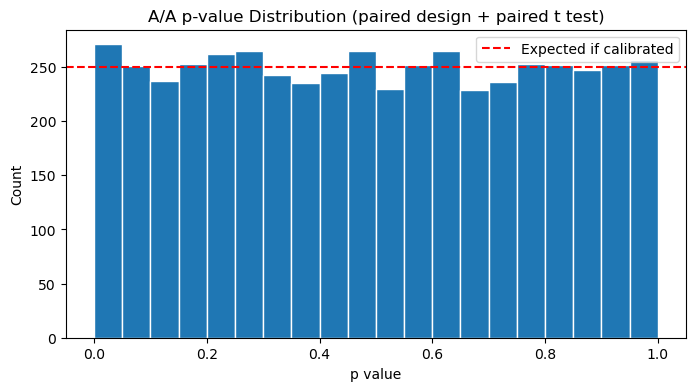

In [40]:
# --- p value distribution for the chosen design ---
p_final = np.array(pvals["Paired + winsorized/cuped + paired t test"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(p_final, bins=20, edgecolor="white")
ax.axhline(B / 20, color="red", linestyle="--", label="Expected if calibrated")
ax.set_title("A/A p-value Distribution (paired design + paired t test)")
ax.set_xlabel("p value")
ax.set_ylabel("Count")
ax.legend()
plt.show()

## 6. Validation by Simulation

### 6A. A/A Test

**Purpose:** Before trusting the design (matched pairs + winsorized p99 + cuped), verify that the full
pipeline (assignment → metric → test) is calibrated. With no treatment applied, every "significant"
result is a false positive, so a calibrated pipeline should reject H₀ about 5% of the time.
- Well above 5%: the pipeline manufactures false discoveries.
- Well below 5%: the pipeline is conservative and wastes power.

**Method:** 5,000 simulated A/A splits of the historical data, comparing five design/analysis combinations,
including two deliberately mismatched ones. With 5,000 simulations, a perfectly calibrated test falls in
[4.4%, 5.6%] (Monte Carlo 95% band).

| Design + analysis | False positive rate | Verdict |
|---|---|---|
| Simple + raw revenue + Welch t-test | 3.1% | Conservative |
| Simple + winsorized/cuped + Welch t-test | 5.4% | ✅ Calibrated |
| Paired + winsorized/cuped + Welch t-test (ignores pairs) | 4.0% | Conservative |
| **Paired + winsorized/cuped + paired t-test (final design)** | **5.4%** | ✅ Calibrated |
| Simple + order level revenue + Welch t-test (wrong unit) | **33.1%** | ❌ Invalid |

The p value distribution of the final design is approximately uniform on [0, 1], as expected under H₀.

**Interpretation**
- **The final design passes.** Its false positive rate is within the Monte Carlo band, and its p-values are
  uniformly distributed.
- **Order level analysis is badly miscalibrated (33% vs. 5%).** Randomization is by customer, so all of a
  customer's orders land in the same group. Treating orders as independent ignores this clustering and
  underestimates the true variance. The effect is severe here because large customers often place several
  large orders, one customer placed two orders of £22,105 and £31,698 on the same day will always fall
  in the same group. **The analysis unit must match the randomization unit:** aggregate to the customer
  level, or use cluster robust standard errors or the delta method.
- **Raw revenue with a t test is conservative (3.1%).** With skewness of 28, ~1,400 customers per group is not
  enough for the normal approximation to fully hold. The test looks "safe" but loses power.
- **Ignoring the pairing is conservative (4.0%).** Pairing reduces the true variance of the difference, but a standard two sample test does not know this and overstates the standard error. The analysis must match the design to realize its benefit.

In [41]:
# --- Power simulation: inject a known lift into the treatment group ---

rng = np.random.default_rng(7)
B_power = 1000
rows = []

for lift in [0.05, 0.10, 0.20, 0.30]:
    hits_raw, hits_final = 0, 0
    for b in range(B_power):
        # Baseline approach: simple randomization, raw revenue
        t = assign_simple(rng)
        y = y_raw * np.where(t, 1 + lift, 1)
        hits_raw += welch_pvalue(y, t) < 0.05

        # Final design: matched pairs, winsorized p99 + cuped, paired t-test
        tp = assign_paired(rng)
        y = y_raw * np.where(tp, 1 + lift, 1)
        hits_final += paired_pvalue(adjust(y), tp) < 0.05

    rows.append({"true_lift": f"{lift:.0%}",
                 "power_simple_raw": f"{hits_raw / B_power:.1%}",
                 "power_final_design": f"{hits_final / B_power:.1%}"})

print(pd.DataFrame(rows).to_string(index=False))

true_lift power_simple_raw power_final_design
       5%             4.8%              10.4%
      10%             4.4%              23.0%
      20%             8.0%              62.6%
      30%            13.0%              91.0%


### 6B. Power Simulation

**Purpose:** The A/A test checks that the pipeline does not produce false positives. The power simulation
checks the other side, when a real effect exists, how often does the pipeline detect it?

**Method:** In each of 1,000 simulations per scenario, customers were randomly assigned, and every treatment customer's revenue was multiplied by (1 + lift) to mimic a true effect. The full pipeline was then applied, and power is the share of simulations with p < 0.05. Compare the two approaches:
- **Baseline:** simple randomization, raw revenue, Welch t test
- **Final design:** matched pairs, winsorized p99 + cuped, paired t test

| True lift | Power: baseline | Power: final design |
|---|---|---|
| 5% | 4.8% | 10.4% |
| 10% | 4.4% | 23.0% |
| 20% | 8.0% | 62.6% |
| 30% | 13.0% | **91.0%** |

**Interpretation**
- **The final design greatly improves power, but only for large effects.** A 30% lift is detected 91% of the time vs. 13% for the baseline. For the plausible ~5% effect, however, power is only about 10%. This means the experiment would almost certainly miss it.
- **The baseline has essentially no detection ability.** At 5% and 10% lifts, its power is about the same as the false positive rate under no effect. Without variance reduction, the experiment is a coin flip.
- **Simulation is more pessimistic than the formula.** Section 5A estimated an MDE of approximately 20% for winsorized p99 cuped, implying 80% power at a 20% lift. Simulation shows only about 63% power at 20%. While reaching 80% requires roughly a 25% lift. The formula assumes the lift applies fully to the analyzed metric, but the lift was applied to *raw* revenue, and winsorization cuts off part of the gain for customers above the cap. Therefore, the trade off noted in 5A "capping can hide real effects" is quantified.

**Takeaway:** With skewed data and a multi-step analysis pipeline, formula based power calculations can be
optimistic. Simulation on historical data gives a more realistic estimate of what the experiment can detect.